# Kickstarter Campaign Success — Data Preparation & EDA

**Tasks covered in this notebook**

| Task | Section |
|---|---|
| 1 — Data ingestion & filtering | [1](#1) |
| 2 — Cleaning & missing values | [2](#2) |
| 4 — Feature engineering | [3](#3) |
| 3 — Feature encoding & scaling | [4](#4) |
| 5 — Exploratory data analysis | [5](#5) |

Tasks 3 and 4 are swapped in execution order on purpose: engineered features (duration, reward-tier
statistics, launch timing) must exist **before** they can be encoded and scaled.

**Source data:** `data/DSI_kickstarterscrape_dataset.csv` (Kickstarter scrape, Kaggle), 45,957 rows x 17 columns.

**Framing:** supervised binary classification, `success = 1` if the campaign was `successful`, `0` if `failed`.
Every feature kept for modeling must be knowable **at launch** — anything produced by the campaign's own
run (pledged, backers, comments, funded percentage) is post-hoc and is dropped as leakage.

In [1]:
import html
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "DSI_kickstarterscrape_dataset.csv"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860", "#DA8BC3"]

RNG_SEED = 42
print("root:", ROOT)

root: /Users/michellelin/StateStreet_BTT_individual


<a id="1"></a>
## 1. Task 1 — Data ingestion and filtering

Three gates, each logged with a row count so the pipeline is auditable and reproducible:

1. **Final outcome only** — keep `successful` / `failed`. `live` campaigns have no outcome yet;
   `canceled` / `suspended` ended by creator or platform action, so their outcome is not a market
   verdict on the campaign and would pollute the label.
2. **US-based only** — the challenge scopes to US campaigns, and `location` is the only geography
   field available.
3. Row counts after each gate are collected into a transformation log printed at the end of Task 2.

In [2]:
raw = pd.read_csv(RAW_PATH, encoding="latin-1")
print("raw shape:", raw.shape)
raw.head(3)

raw shape: (45957, 17)


,project id,name,url,category,subcategory,location,status,goal,pledged,funded percentage,backers,funded date,levels,reward levels,updates,comments,duration
0,39409,WHILE THE TREES SLEEP,http://www.kickstarter.com/projects/emiliesaba...,Film & Video,Short Film,"Columbia, MO",successful,10500.0,11545.0,1.099524,66,"Fri, 19 Aug 2011 19:28:17 -0000",7,"$25,$50,$100,$250,$500,$1,000,$2,500",10,2,30.00
1,126581,Educational Online Trading Card Game,http://www.kickstarter.com/projects/972789543/...,Games,Board & Card Games,"Maplewood, NJ",failed,4000.0,20.0,0.005000,2,"Mon, 02 Aug 2010 03:59:00 -0000",5,"$1,$5,$10,$25,$50",6,0,47.18
2,138119,STRUM,http://www.kickstarter.com/projects/185476022/...,Film & Video,Animation,"Los Angeles, CA",live,20000.0,56.0,0.002800,3,"Fri, 08 Jun 2012 00:00:31 -0000",10,"$1,$10,$25,$40,$50,$100,$250,$1,000,$1,337,$9,001",1,0,28.00


In [3]:
print(raw.dtypes.to_string())
print()
print("status counts:")
print(raw["status"].value_counts(dropna=False).to_string())
print()
print("missing values per column:")
miss = raw.isna().sum()
print(miss[miss > 0].to_string() if (miss > 0).any() else "(none)")

project id             int64
name                     str
url                      str
category                 str
subcategory              str
location                 str
status                   str
goal                 float64
pledged              float64
funded percentage    float64
backers                int64
funded date              str
levels                 int64
reward levels            str
updates                int64
comments               int64
duration             float64

status counts:
status
successful    22969
failed        18996
live           3929
canceled         59
suspended         4

missing values per column:
location         1322
pledged            12
reward levels      59


In [4]:
LOG = []
def log_step(label, frame):
    LOG.append((label, len(frame)))
    print(f"{label:<45} {len(frame):>7,} rows")

log_step("0. Raw data", raw)

0. Raw data                                    45,957 rows


### 1.1 Keep only campaigns with a final outcome

In [5]:
df = raw[raw["status"].isin(["successful", "failed"])].copy()
log_step("1. Keep successful / failed", df)
print()
print(df["status"].value_counts(normalize=True).round(3).to_string())

1. Keep successful / failed                    41,965 rows

status
successful    0.547
failed        0.453


### 1.2 Repair HTML-escaped text before any string matching

Some labels were scraped with HTML entities intact, so `Film &amp; Video` and `Film & Video` appear as
two distinct categories. Unescaping first prevents a spurious category split and prevents a location
such as `Coeur d&#39;Alene, ID` from failing the state parse below.

In [6]:
text_cols = ["name", "category", "subcategory", "location"]
before_cats = df["category"].nunique()
for col in text_cols:
    df[col] = df[col].map(lambda s: html.unescape(s) if isinstance(s, str) else s)
print(f"categories: {before_cats} -> {df['category'].nunique()} after unescaping")
print(sorted(df["category"].dropna().unique()))

categories: 14 -> 13 after unescaping
['Art', 'Comics', 'Dance', 'Design', 'Fashion', 'Film & Video', 'Food', 'Games', 'Music', 'Photography', 'Publishing', 'Technology', 'Theater']


### 1.3 Filter to US-based campaigns

`location` is a free-text `"City, Region"` string. US rows end in a two-letter USPS state code
(including `DC`); international rows end in a country or region name (`"London, UK"`,
`"Toronto, Canada"`). Matching the trailing token against the official state set is therefore both the
US filter and the first half of the City/State split required by Task 2.

In [7]:
US_STATES = {
    "AL","AK","AZ","AR","CA","CO","CT","DE","DC","FL","GA","HI","ID","IL","IN","IA",
    "KS","KY","LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM",
    "NY","NC","ND","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT","VA","WA",
    "WV","WI","WY",
}

loc_parts = df["location"].str.rsplit(",", n=1, expand=True)
df["city"] = loc_parts[0].str.strip()
df["state"] = loc_parts[1].str.strip().str.upper()

non_us_examples = df.loc[~df["state"].isin(US_STATES), "location"].dropna().value_counts().head(8)
print("examples of rows dropped as non-US / unparseable:")
print(non_us_examples.to_string())
print()

df = df[df["state"].isin(US_STATES)].copy()
log_step("2. Keep US campaigns (valid state code)", df)
print(f"\n{df['state'].nunique()} distinct states (incl. DC), {df['city'].nunique():,} distinct cities")

examples of rows dropped as non-US / unparseable:
location
London, United Kingdom       98
Toronto, Canada              84
Vancouver, Canada            65
Berlin, Germany              61
Paris, France                55
MontrÛÎ©al, Canada          37
Edinburgh, United Kingdom    30
Port Au Prince, Haiti        24

2. Keep US campaigns (valid state code)        38,533 rows

51 distinct states (incl. DC), 3,155 distinct cities


<a id="2"></a>
## 2. Task 2 — Cleaning and missing values

Order of operations: split location (done above, since it doubled as the US filter) -> inspect and
treat missing values -> drop free-text and post-outcome columns -> build the label.

### 2.1 City / State split — verification

In [8]:
df[["location", "city", "state"]].head(8)

,location,city,state
0,"Columbia, MO",Columbia,MO
1,"Maplewood, NJ",Maplewood,NJ
3,"Los Angeles, CA",Los Angeles,CA
4,"Novi, MI",Novi,MI
5,"Portland, OR",Portland,OR
6,"Collegedale, TN",Collegedale,TN
7,"Chicago, IL",Chicago,IL
8,"Chicago, IL",Chicago,IL


In [9]:
print("top 10 states by campaign count:")
print(df["state"].value_counts().head(10).to_string())
print("\ntop 10 cities:")
print(df["city"].value_counts().head(10).to_string())

top 10 states by campaign count:
state
CA    8220
NY    6639
TX    1847
IL    1720
FL    1410
WA    1273
MA    1220
PA    1205
OR    1179
GA     965

top 10 cities:
city
Los Angeles      3641
New York         3434
Brooklyn         1524
Chicago          1383
San Francisco    1243
Portland         1015
Seattle           857
Austin            760
Boston            724
Nashville         631


### 2.2 Missing values

Remaining nulls after the filters are inspected column by column and treated according to what the
column means, rather than with one blanket rule.

In [10]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
report = pd.DataFrame({"n_missing": miss, "pct": (miss / len(df) * 100).round(3)})
print(report.to_string() if len(report) else "(no missing values remain)")

               n_missing    pct
reward levels         41  0.106


In [11]:
# Treatment, by column meaning:
#   reward levels / levels : a campaign with no parseable reward tiers cannot support the
#                            reward-based features this project depends on -> drop the row.
#   updates / comments     : a blank means "none posted" -> fill with 0.
#   goal, duration         : core numeric fields, no sensible imputation -> drop the row.
for col in ["updates", "comments"]:
    if col in df.columns:
        df[col] = df[col].fillna(0)

essential = ["goal", "duration", "levels", "reward levels", "category", "subcategory", "funded date"]
before = len(df)
df = df.dropna(subset=[c for c in essential if c in df.columns]).reset_index(drop=True)
print(f"dropped {before - len(df):,} rows with nulls in essential columns "
      f"({(before - len(df)) / before * 100:.2f}%)")
log_step("3. Drop rows missing essential fields", df)

dropped 41 rows with nulls in essential columns (0.11%)
3. Drop rows missing essential fields          38,492 rows


### 2.3 Sanity checks on value ranges

Non-positive goals or durations are not meaningful campaigns and would distort both the log transform
and the per-day pacing features built in Task 4.

In [12]:
print("goal      :", df["goal"].describe([.01, .5, .99]).round(2).to_dict())
print("duration  :", df["duration"].describe([.01, .5, .99]).round(2).to_dict())
print("levels    :", df["levels"].describe().round(2).to_dict())

bad = (df["goal"] <= 0) | (df["duration"] <= 0)
print(f"\nnon-positive goal or duration: {bad.sum():,} rows")
df = df[~bad].reset_index(drop=True)
log_step("4. Drop non-positive goal / duration", df)

goal      : {'count': 38492.0, 'mean': 10480.26, 'std': 154042.45, 'min': 0.5, '1%': 200.0, '50%': 4000.0, '99%': 97000.0, 'max': 21474836.47}
duration  : {'count': 38492.0, 'mean': 39.8, 'std': 17.43, 'min': 1.0, '1%': 9.86, '50%': 31.88, '99%': 90.04, 'max': 91.96}
levels    : {'count': 38492.0, 'mean': 8.0, 'std': 4.21, 'min': 1.0, '25%': 5.0, '50%': 7.0, '75%': 10.0, 'max': 80.0}

non-positive goal or duration: 0 rows
4. Drop non-positive goal / duration           38,492 rows


### 2.4 Build the target label

In [13]:
df["success"] = (df["status"] == "successful").astype(int)
print(df["success"].value_counts().to_string())
print(f"\nbase success rate: {df['success'].mean():.3%}  (classes are close to balanced)")

success
1    21066
0    17426

base success rate: 54.728%  (classes are close to balanced)


### 2.5 Drop unnecessary text fields and leakage columns

Two separate reasons for removal, kept separate because they are different kinds of problem:

**Free-text / identifier columns** carry no model signal in their raw form and are dropped per Task 2:

| Column | Why removed |
|---|---|
| `project id` | Row identifier, arbitrary |
| `name` | Free text; would need NLP features, out of scope here |
| `url` | Identifier/free text, one unique value per row |
| `location` | Fully replaced by the `city` / `state` split |
| `reward levels` | Raw text; replaced by the numeric tier features built in Task 4 |

**Leakage columns** are only observable *after* the campaign runs. Keeping them would produce a model
that looks excellent offline and is useless at launch, since `funded percentage >= 1` *is* the label:

| Column | Why it leaks |
|---|---|
| `pledged`, `funded percentage` | Mechanically determine the outcome |
| `backers`, `comments` | Accumulate during the campaign |
| `status` | The label itself |

`funded date` is also post-hoc, but it is the campaign **deadline**, and deadline minus duration
recovers the **launch date** — a genuinely pre-launch quantity. It is therefore retained through
Task 4 and dropped only after launch-timing features are derived.

In [14]:
TEXT_DROP = ["project id", "name", "url", "location"]
LEAKY = ["pledged", "funded percentage", "backers", "comments", "status"]

clean = df.copy()
print("columns retained into Task 4:")
print([c for c in clean.columns if c not in TEXT_DROP + LEAKY])

columns retained into Task 4:
['category', 'subcategory', 'goal', 'funded date', 'levels', 'reward levels', 'updates', 'duration', 'city', 'state', 'success']


### 2.6 Preprocessing log

In [15]:
log_df = pd.DataFrame(LOG, columns=["step", "rows_after"])
log_df["rows_removed"] = log_df["rows_after"].diff().fillna(0).astype(int).abs()
log_df["pct_of_raw"] = (log_df["rows_after"] / LOG[0][1] * 100).round(2)
log_df

,step,rows_after,rows_removed,pct_of_raw
0,0. Raw data,45957,0,100.00
1,1. Keep successful / failed,41965,3992,91.31
2,2. Keep US campaigns (valid state code),38533,3432,83.85
3,3. Drop rows missing essential fields,38492,41,83.76
4,4. Drop non-positive goal / duration,38492,0,83.76


<a id="3"></a>
## 3. Task 4 — Feature engineering

Every feature below is constrained to the **pre-launch / at-launch** information set. The guiding
question for each candidate is: *could a creator compute this the moment they press Launch?*

| Feature | Definition | Available at launch? |
|---|---|---|
| `duration_days` | deadline − launch, in days | Yes — the creator chooses it |
| `launch_year`, `launch_month`, `launch_dow`, `launch_quarter` | calendar position of the launch date | Yes |
| `goal_log` | `log1p(goal)` — goals span $1 to $21M | Yes |
| `n_reward_tiers` | count of reward levels offered | Yes |
| `reward_min`, `reward_max`, `reward_mean`, `reward_median`, `reward_spread` | reward tier price statistics | Yes |
| `goal_per_day` | goal / duration — required daily fundraising pace | Yes |
| `is_default_30d` | campaign length is exactly the platform default of 30 days | Yes |
| `backers_needed_at_mean_reward` | goal / mean reward price — how many backers the plan implies | Yes |
| `update_frequency` | updates / duration_days | **No — leakage**, built for the EDA only |

`update_frequency` is included because Task 4 names it explicitly, but updates are posted *during* the
campaign. It is computed, flagged, quarantined in a separate column list, and excluded from the
model-ready matrix.

### 3.1 Campaign duration (launch -> deadline)

`funded date` is the deadline timestamp. The dataset already ships a `duration` column; it is
recomputed from the dates independently and cross-checked rather than trusted blindly.

In [16]:
clean["deadline"] = pd.to_datetime(clean["funded date"], format="mixed", utc=True, errors="coerce")
print("unparseable deadlines:", clean["deadline"].isna().sum())

clean["launch_date"] = clean["deadline"] - pd.to_timedelta(clean["duration"], unit="D")
clean["duration_days"] = (clean["deadline"] - clean["launch_date"]).dt.total_seconds() / 86400

agree = np.isclose(clean["duration_days"], clean["duration"], atol=1e-6)
print(f"recomputed duration matches shipped `duration`: {agree.mean():.2%}")
print(f"\ndeadline range : {clean['deadline'].min().date()} -> {clean['deadline'].max().date()}")
print(f"launch range   : {clean['launch_date'].min().date()} -> {clean['launch_date'].max().date()}")
clean[["launch_date", "deadline", "duration", "duration_days"]].head()

unparseable deadlines: 0
recomputed duration matches shipped `duration`: 100.00%

deadline range : 2009-05-16 -> 2012-06-03
launch range   : 2009-04-21 -> 2012-05-29


,launch_date,deadline,duration,duration_days
0,2011-07-20 19:28:17+00:00,2011-08-19 19:28:17+00:00,30.00,30.00
1,2010-06-15 23:39:48+00:00,2010-08-02 03:59:00+00:00,47.18,47.18
2,2012-03-06 20:57:12+00:00,2012-04-08 02:14:00+00:00,32.22,32.22
3,2011-05-02 15:25:39+00:00,2011-06-01 15:25:39+00:00,30.00,30.00
4,2011-06-01 03:13:48+00:00,2011-06-22 13:33:00+00:00,21.43,21.43


### 3.2 Launch timing features

Seasonality is a real, actionable lever: a creator picking a launch week can act on it.

In [17]:
clean["launch_year"] = clean["launch_date"].dt.year
clean["launch_month"] = clean["launch_date"].dt.month
clean["launch_dow"] = clean["launch_date"].dt.dayofweek      # 0 = Monday
clean["launch_quarter"] = clean["launch_date"].dt.quarter
clean[["launch_year", "launch_month", "launch_dow", "launch_quarter"]].describe().round(2)

,launch_year,launch_month,launch_dow,launch_quarter
count,38492.00,38492.00,38492.00,38492.00
mean,2011.07,5.91,2.58,2.31
std,0.73,3.51,1.82,1.15
min,2009.00,1.00,0.00,1.00
25%,2011.00,3.00,1.00,1.00
50%,2011.00,5.00,2.00,2.00
75%,2012.00,9.00,4.00,3.00
max,2012.00,12.00,6.00,4.00


### 3.3 Reward tier features

`reward levels` is a comma-joined list of dollar amounts where the amounts themselves contain commas
(`"$25,$1,000,$2,500"`). A naive `split(",")` shatters `$1,000` into `$1` and `000`. The regex below
anchors each amount to a `$` and requires the next character to be either a following `$`-amount or
the end of the string, so thousands separators survive intact.

In [18]:
AMOUNT_RE = re.compile(r"\$\s*([\d,]+(?:\.\d+)?)(?=\s*,\s*\$|\s*$)")

def parse_reward_tiers(text):
    if not isinstance(text, str):
        return []
    out = []
    for a in AMOUNT_RE.findall(text):
        try:
            v = float(a.replace(",", ""))
        except ValueError:
            continue
        if v > 0:
            out.append(v)
    return out

# spot-check the parser against the tricky thousands-separator case
for sample in ['$25,$50,$100,$250,$500,$1,000,$2,500', '$1,$5,$10,$25,$50', '$10,$10,000']:
    print(f"{sample:<42} -> {parse_reward_tiers(sample)}")

$25,$50,$100,$250,$500,$1,000,$2,500       -> [25.0, 50.0, 100.0, 250.0, 500.0, 1000.0, 2500.0]
$1,$5,$10,$25,$50                          -> [1.0, 5.0, 10.0, 25.0, 50.0]
$10,$10,000                                -> [10.0, 10000.0]


In [19]:
tiers = clean["reward levels"].map(parse_reward_tiers)

clean["n_reward_tiers"] = tiers.map(len)
clean["reward_min"] = tiers.map(lambda t: min(t) if t else np.nan)
clean["reward_max"] = tiers.map(lambda t: max(t) if t else np.nan)
clean["reward_mean"] = tiers.map(lambda t: float(np.mean(t)) if t else np.nan)
clean["reward_median"] = tiers.map(lambda t: float(np.median(t)) if t else np.nan)
clean["reward_spread"] = clean["reward_max"] - clean["reward_min"]

print(f"rows with zero parseable tiers: {(clean['n_reward_tiers'] == 0).sum():,}")
print("\nagreement between parsed tier count and the shipped `levels` column:",
      f"{(clean['n_reward_tiers'] == clean['levels']).mean():.2%}")

before = len(clean)
clean = clean[clean["n_reward_tiers"] > 0].reset_index(drop=True)
print(f"\ndropped {before - len(clean):,} rows with no parseable reward tier")
log_step("5. Drop rows with no parseable reward tier", clean)

rows with zero parseable tiers: 0

agreement between parsed tier count and the shipped `levels` column: 100.00%

dropped 0 rows with no parseable reward tier
5. Drop rows with no parseable reward tier     38,492 rows


In [20]:
clean[["reward_min", "reward_median", "reward_mean", "reward_max",
       "reward_spread", "n_reward_tiers"]].describe().round(2)

,reward_min,reward_median,reward_mean,reward_max,reward_spread,n_reward_tiers
count,38492.00,38492.00,38492.00,38492.00,38492.00,38492.00
mean,8.96,103.96,388.25,1940.64,1931.68,8.00
std,96.96,186.64,509.59,2732.73,2732.05,4.21
min,1.00,1.00,1.00,1.00,0.00,1.00
25%,1.00,37.50,81.00,250.00,245.00,5.00
50%,5.00,75.00,208.33,1000.00,990.00,7.00
75%,10.00,100.00,457.18,2100.00,2019.25,10.00
max,10000.00,10000.00,10000.00,10000.00,9999.00,80.00


### 3.4 Derived ratio features

These encode the *plausibility of the plan itself*, which is exactly what a pre-launch advisor would
assess: how much money per day the campaign must raise, and how many backers that implies at the
average reward price.

In [21]:
clean["goal_log"] = np.log1p(clean["goal"])
clean["goal_per_day"] = clean["goal"] / clean["duration_days"]
clean["backers_needed_at_mean_reward"] = clean["goal"] / clean["reward_mean"]
clean["reward_min_to_goal"] = clean["reward_min"] / clean["goal"]
# 30 days is the platform default; a campaign sitting exactly on it most likely accepted
# the default rather than chose a length. Flagging it separates "chose 30" from "chose 31".
clean["is_default_30d"] = (clean["duration_days"].round(2) == 30.0).astype(int)

# Named by Task 4 but post-launch: computed, flagged, kept out of the model matrix.
clean["update_frequency"] = clean["updates"] / clean["duration_days"]
LEAKY_ENGINEERED = ["update_frequency", "updates"]

clean[["goal", "goal_log", "goal_per_day", "backers_needed_at_mean_reward",
       "update_frequency"]].describe().round(3)

,goal,goal_log,goal_per_day,backers_needed_at_mean_reward,update_frequency
count,3.849200e+04,38492.000,38492.000,38492.000,38492.000
mean,1.048026e+04,8.227,264.581,131.333,0.124
std,1.540424e+05,1.300,2012.399,4962.763,0.213
min,5.000000e-01,0.405,0.014,0.000,0.000
25%,1.600000e+03,7.378,46.667,9.375,0.000
50%,4.000000e+03,8.294,100.000,18.038,0.056
75%,8.500000e+03,9.048,223.161,37.037,0.167
max,2.147484e+07,16.882,258421.618,858993.459,12.871


### 3.5 Assemble the feature set

In [22]:
NUMERIC_FEATURES = [
    "goal", "goal_log", "duration_days", "goal_per_day",
    "n_reward_tiers", "reward_min", "reward_max", "reward_mean", "reward_median",
    "reward_spread", "backers_needed_at_mean_reward", "reward_min_to_goal",
    "launch_year", "launch_month", "launch_dow", "launch_quarter", "is_default_30d",
]
ONEHOT_FEATURES = ["category"]          # 13 levels  -> one-hot
TARGET_ENC_FEATURES = ["subcategory", "state"]   # 100+ and 51 levels -> target encoding
TARGET = "success"

features = clean[NUMERIC_FEATURES + ONEHOT_FEATURES + TARGET_ENC_FEATURES].copy()
y = clean[TARGET].copy()

print(f"feature matrix: {features.shape[0]:,} rows x {features.shape[1]} columns")
print(f"  numeric      : {len(NUMERIC_FEATURES)}")
print(f"  one-hot      : {ONEHOT_FEATURES} -> {clean['category'].nunique()} levels")
print(f"  target-encode: {TARGET_ENC_FEATURES} -> "
      f"{clean['subcategory'].nunique()} / {clean['state'].nunique()} levels")
print(f"\nremaining nulls in feature matrix: {int(features.isna().sum().sum())}")

feature matrix: 38,492 rows x 20 columns
  numeric      : 17
  one-hot      : ['category'] -> 13 levels
  target-encode: ['subcategory', 'state'] -> 49 / 51 levels

remaining nulls in feature matrix: 0


<a id="4"></a>
## 4. Task 3 — Feature encoding and scaling

**Encoding strategy, chosen per column by cardinality:**

| Column | Levels | Encoding | Reason |
|---|---|---|---|
| `category` | 13 | One-hot | Low cardinality; one-hot is lossless and keeps coefficients directly interpretable |
| `subcategory` | ~110 | Target encoding | One-hot would add ~110 sparse columns; target encoding keeps it to one dense, ordered column |
| `state` | 51 | Target encoding | Same reasoning; also preserves the ordering of state-level success rates |

**Scaling:** `StandardScaler` on all numeric columns. Goal and the reward amounts are heavily
right-skewed, so `goal_log` is carried alongside raw `goal`, and skewed money columns get a log
transform *before* standardization.

**Leakage discipline in the encoder itself.** Target encoding looks at `y`, so fitting it on the full
dataset leaks label information into the training features. Two guards:

1. The train/test split happens **before** any encoder or scaler is fitted.
2. `TargetEncoder` is used with internal cross-fitting, so each training row's encoded value comes
   from folds that exclude it.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    features, y, test_size=0.20, random_state=RNG_SEED, stratify=y
)
print(f"train: {X_train.shape[0]:,} rows   test: {X_test.shape[0]:,} rows")
print(f"success rate — train {y_train.mean():.3f} / test {y_test.mean():.3f} (stratified)")

train: 30,793 rows   test: 7,699 rows
success rate — train 0.547 / test 0.547 (stratified)


In [24]:
# Money columns are right-skewed; log1p before standardizing so the scaler is not dominated
# by a handful of multi-million-dollar goals and $10,000 reward tiers.
SKEWED = ["goal", "goal_per_day", "reward_min", "reward_max", "reward_mean",
          "reward_median", "reward_spread", "backers_needed_at_mean_reward"]
PLAIN_NUMERIC = [c for c in NUMERIC_FEATURES if c not in SKEWED]

log_then_scale = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("skewed_num", log_then_scale, SKEWED),
        ("num", StandardScaler(), PLAIN_NUMERIC),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=0.005, sparse_output=False), ONEHOT_FEATURES),
        ("target_enc", Pipeline([
            ("enc", TargetEncoder(target_type="binary", cv=5, random_state=RNG_SEED)),
            ("scale", StandardScaler()),
        ]), TARGET_ENC_FEATURES),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_enc = preprocessor.fit_transform(X_train, y_train)   # fit on TRAIN only
X_test_enc = preprocessor.transform(X_test)                  # test is transform-only
feat_names = preprocessor.get_feature_names_out()

print(f"encoded train matrix: {X_train_enc.shape}")
print(f"encoded test  matrix: {X_test_enc.shape}")
print(f"\n{len(feat_names)} output features:")
print(list(feat_names))

encoded train matrix: (30793, 32)
encoded test  matrix: (7699, 32)

32 output features:
['goal', 'goal_per_day', 'reward_min', 'reward_max', 'reward_mean', 'reward_median', 'reward_spread', 'backers_needed_at_mean_reward', 'goal_log', 'duration_days', 'n_reward_tiers', 'reward_min_to_goal', 'launch_year', 'launch_month', 'launch_dow', 'launch_quarter', 'is_default_30d', 'category_Art', 'category_Comics', 'category_Dance', 'category_Design', 'category_Fashion', 'category_Film & Video', 'category_Food', 'category_Games', 'category_Music', 'category_Photography', 'category_Publishing', 'category_Technology', 'category_Theater', 'subcategory', 'state']


In [25]:
enc_train = pd.DataFrame(X_train_enc, columns=feat_names, index=X_train.index)
enc_test = pd.DataFrame(X_test_enc, columns=feat_names, index=X_test.index)

check = enc_train.describe().T[["mean", "std", "min", "max"]].round(3)
print("scaling check — standardized columns should sit at mean 0 / std 1:")
print(check.head(20).to_string())

scaling check — standardized columns should sit at mean 0 / std 1:
                                mean    std    min      max
goal                           0.000  1.000 -5.781    6.640
goal_per_day                   0.000  1.000 -3.778    6.348
reward_min                     0.000  1.000 -1.056    8.212
reward_max                     0.000  1.000 -3.593    1.636
reward_mean                   -0.000  1.000 -3.564    3.101
reward_median                 -0.000  1.000 -3.974    5.607
reward_spread                 -0.000  1.000 -3.485    1.493
backers_needed_at_mean_reward -0.000  1.000 -2.724    9.360
goal_log                       0.000  1.000 -5.781    6.640
duration_days                 -0.000  1.000 -2.227    2.992
n_reward_tiers                -0.000  1.000 -1.667   16.218
reward_min_to_goal             0.000  1.000 -0.019  149.876
launch_year                    0.000  1.000 -2.833    1.277
launch_month                   0.000  1.000 -1.397    1.735
launch_dow                     0.

In [26]:
# What target encoding learned: state and subcategory collapse to a single ordered column each.
te_preview = pd.DataFrame({
    "state": X_train["state"],
    "state_encoded": enc_train["state"],
    "subcategory": X_train["subcategory"],
    "subcategory_encoded": enc_train["subcategory"],
})
print("highest-scoring states by target encoding:")
print(te_preview.groupby("state")["state_encoded"].mean().sort_values(ascending=False).head(5).round(3).to_string())
print("\nlowest:")
print(te_preview.groupby("state")["state_encoded"].mean().sort_values().head(5).round(3).to_string())

highest-scoring states by target encoding:
state
VT    1.948
RI    1.496
NY    1.347
ND    1.022
MA    0.979

lowest:
state
WY   -4.844
HI   -2.376
DE   -2.287
FL   -2.277
OK   -2.275


### 4.1 Persist the prepared datasets

In [27]:
clean_out = clean.drop(columns=[c for c in TEXT_DROP + LEAKY if c in clean.columns])
clean_out.to_csv(PROC_DIR / "kickstarter_us_clean.csv", index=False)

enc_train.assign(success=y_train.values).to_csv(PROC_DIR / "train_encoded.csv", index=False)
enc_test.assign(success=y_test.values).to_csv(PROC_DIR / "test_encoded.csv", index=False)

print("wrote:")
for p in ["kickstarter_us_clean.csv", "train_encoded.csv", "test_encoded.csv"]:
    f = PROC_DIR / p
    print(f"  {f.relative_to(ROOT)}  ({f.stat().st_size / 1e6:.1f} MB)")
print(f"\nclean (EDA) frame: {clean_out.shape}   encoded train: {enc_train.shape}")

wrote:
  data/processed/kickstarter_us_clean.csv  (12.0 MB)
  data/processed/train_encoded.csv  (13.2 MB)
  data/processed/test_encoded.csv  (3.3 MB)

clean (EDA) frame: (38492, 30)   encoded train: (30793, 32)


<a id="5"></a>
## 5. Task 5 — Exploratory data analysis

EDA runs on the **clean, unscaled** frame so that axes stay in real units (dollars, days, percent).
All figures are written to `figures/`.

### 5.1 Summary statistics

In [28]:
eda = clean.copy()
BASE = eda["success"].mean()
print(f"{len(eda):,} campaigns, base success rate {BASE:.2%}\n")

summary_cols = ["goal", "duration_days", "n_reward_tiers", "reward_min", "reward_mean",
                "reward_max", "goal_per_day", "backers_needed_at_mean_reward", "updates"]
eda[summary_cols].describe([.05, .25, .5, .75, .95]).T.round(2)

38,492 campaigns, base success rate 54.73%



,count,mean,std,min,5%,25%,50%,75%,95%,max
goal,38492.0,10480.26,154042.45,0.50,500.00,1600.00,4000.00,8500.00,30000.00,21474836.47
duration_days,38492.0,39.80,17.43,1.00,17.07,30.00,31.88,47.41,77.20,91.96
n_reward_tiers,38492.0,8.00,4.21,1.00,3.00,5.00,7.00,10.00,15.00,80.00
reward_min,38492.0,8.96,96.96,1.00,1.00,1.00,5.00,10.00,25.00,10000.00
reward_mean,38492.0,388.25,509.59,1.00,22.27,81.00,208.33,457.18,1553.37,10000.00
reward_max,38492.0,1940.64,2732.73,1.00,50.00,250.00,1000.00,2100.00,10000.00,10000.00
goal_per_day,38492.0,264.58,2012.40,0.01,14.36,46.67,100.00,223.16,832.78,258421.62
backers_needed_at_mean_reward,38492.0,131.33,4962.76,0.00,3.76,9.38,18.04,37.04,157.49,858993.46
updates,38492.0,4.29,6.55,0.00,0.00,0.00,2.00,6.00,16.00,149.00


In [29]:
# Split summary statistics by outcome — the single most informative table in the EDA.
by_outcome = eda.groupby("success")[summary_cols].median().T
by_outcome.columns = ["failed (median)", "successful (median)"]
by_outcome["ratio"] = (by_outcome["successful (median)"] / by_outcome["failed (median)"]).round(2)
by_outcome.round(2)

,failed (median),successful (median),ratio
goal,5000.00,3000.00,0.60
duration_days,35.00,30.96,0.88
n_reward_tiers,7.00,8.00,1.14
reward_min,5.00,5.00,1.00
reward_mean,215.00,202.09,0.94
reward_max,1000.00,1000.00,1.00
goal_per_day,140.00,83.33,0.60
backers_needed_at_mean_reward,24.68,14.89,0.60
updates,0.00,5.00,inf


### 5.2 Distribution of goal, and goal vs. success

Goals span six orders of magnitude, so the distribution is plotted on a log axis.

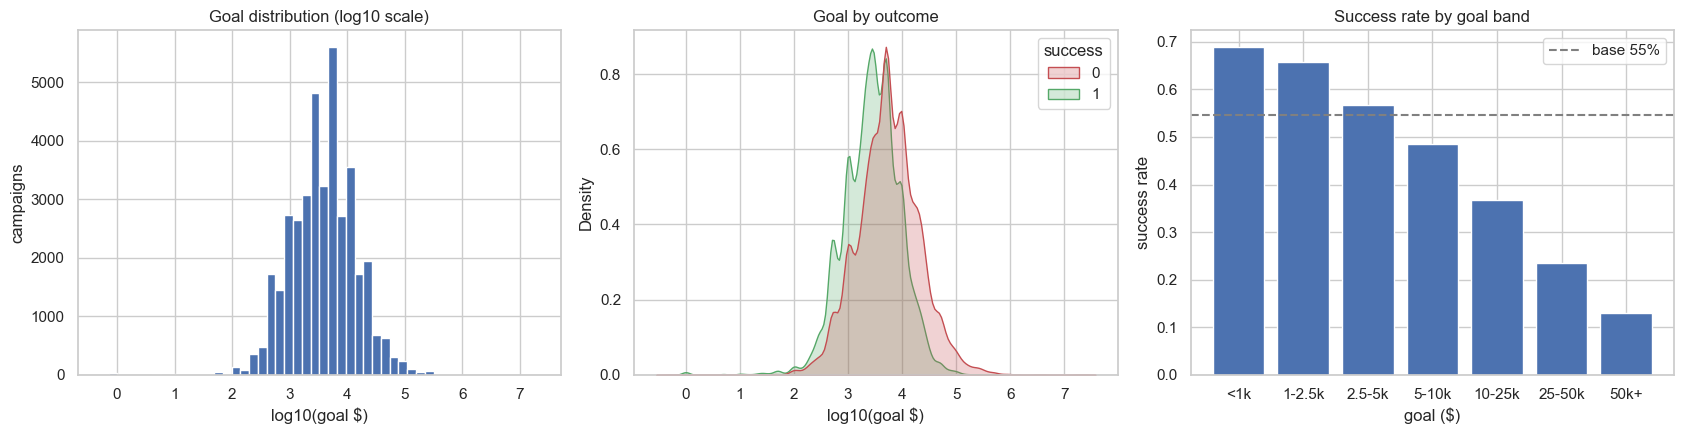

            mean  size
goal_band             
<1k        0.690  6883
1-2.5k     0.657  7916
2.5-5k     0.566  9724
5-10k      0.485  7166
10-25k     0.367  4658
25-50k     0.235  1338
50k+       0.130   807


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(np.log10(eda["goal"]), bins=50, color=PALETTE[0], edgecolor="white")
axes[0].set(title="Goal distribution (log10 scale)", xlabel="log10(goal $)", ylabel="campaigns")

sns.kdeplot(data=eda, x=np.log10(eda["goal"]), hue="success", fill=True,
            common_norm=False, palette=[PALETTE[3], PALETTE[2]], ax=axes[1])
axes[1].set(title="Goal by outcome", xlabel="log10(goal $)")

bins = [0, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, np.inf]
labels = ["<1k", "1-2.5k", "2.5-5k", "5-10k", "10-25k", "25-50k", "50k+"]
eda["goal_band"] = pd.cut(eda["goal"], bins=bins, labels=labels)
gr = eda.groupby("goal_band", observed=True)["success"].agg(["mean", "size"])
axes[2].bar(gr.index.astype(str), gr["mean"], color=PALETTE[0])
axes[2].axhline(BASE, ls="--", c="gray", label=f"base {BASE:.0%}")
axes[2].set(title="Success rate by goal band", xlabel="goal ($)", ylabel="success rate")
axes[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_goal.png", dpi=150); plt.show()

print(gr.assign(mean=lambda d: d["mean"].round(3)).to_string())

### 5.3 Distribution of duration, and duration vs. success

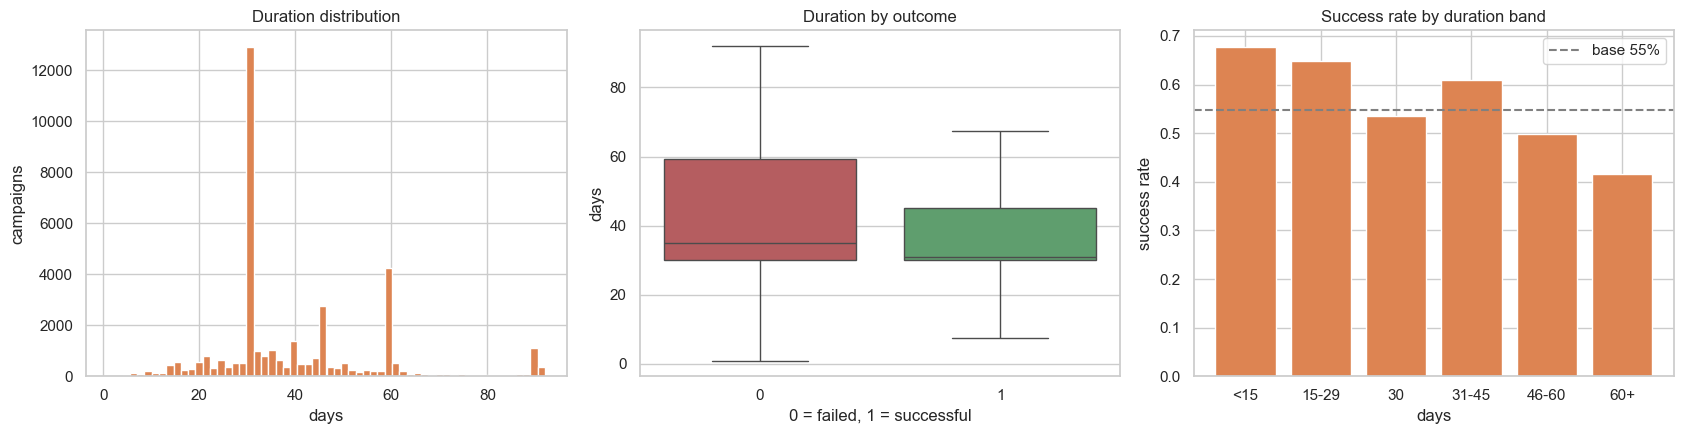

                mean   size
duration_band              
<15            0.678   1284
15-29          0.649   6162
30             0.536  10724
31-45          0.610   7724
46-60          0.498   6129
60+            0.416   6469


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(eda["duration_days"], bins=60, color=PALETTE[1], edgecolor="white")
axes[0].set(title="Duration distribution", xlabel="days", ylabel="campaigns")

sns.boxplot(data=eda, x="success", y="duration_days", ax=axes[1],
            palette=[PALETTE[3], PALETTE[2]], showfliers=False)
axes[1].set(title="Duration by outcome", xlabel="0 = failed, 1 = successful", ylabel="days")

eda["duration_band"] = pd.cut(eda["duration_days"], bins=[0, 15, 30, 31, 45, 60, np.inf],
                              labels=["<15", "15-29", "30", "31-45", "46-60", "60+"], right=False)
dr = eda.groupby("duration_band", observed=True)["success"].agg(["mean", "size"])
axes[2].bar(dr.index.astype(str), dr["mean"], color=PALETTE[1])
axes[2].axhline(BASE, ls="--", c="gray", label=f"base {BASE:.0%}")
axes[2].set(title="Success rate by duration band", xlabel="days", ylabel="success rate")
axes[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_duration.png", dpi=150); plt.show()

print(dr.assign(mean=lambda d: d["mean"].round(3)).to_string())

### 5.4 Success rate across categories

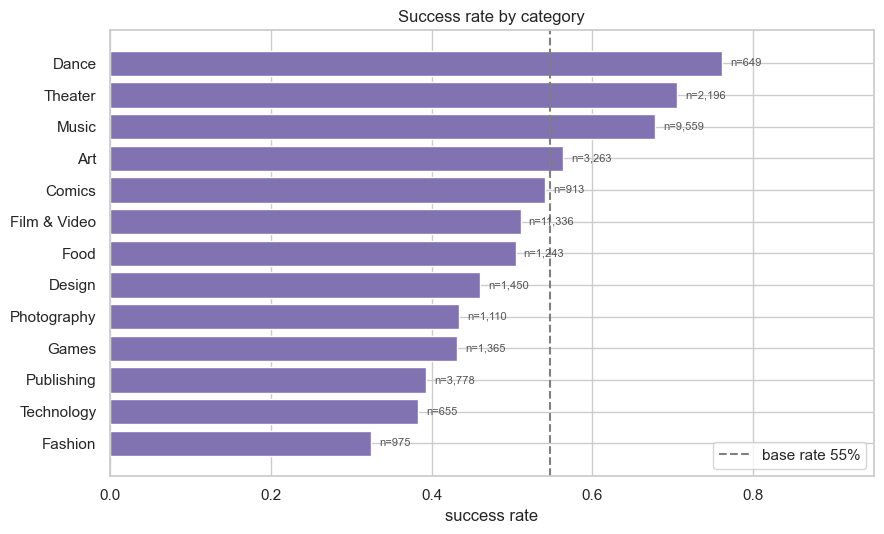

               mean   size
category                  
Fashion       0.325    975
Technology    0.383    655
Publishing    0.393   3778
Games         0.432   1365
Photography   0.434   1110
Design        0.460   1450
Food          0.504   1243
Film & Video  0.511  11336
Comics        0.541    913
Art           0.564   3263
Music         0.678   9559
Theater       0.705   2196
Dance         0.761    649


In [32]:
cat = eda.groupby("category")["success"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(cat.index, cat["mean"], color=PALETTE[4])
ax.axvline(BASE, ls="--", c="gray", label=f"base rate {BASE:.0%}")
for i, (m, n) in enumerate(zip(cat["mean"], cat["size"])):
    ax.text(m + 0.01, i, f"n={n:,}", va="center", fontsize=8, color="#555")
ax.set(title="Success rate by category", xlabel="success rate", xlim=(0, 0.95))
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_category.png", dpi=150); plt.show()

print(cat.assign(mean=lambda d: d["mean"].round(3)).to_string())

### 5.5 Success rate across states

Restricted to states with at least 200 campaigns, so the bars are not dominated by sampling noise
from low-volume states.

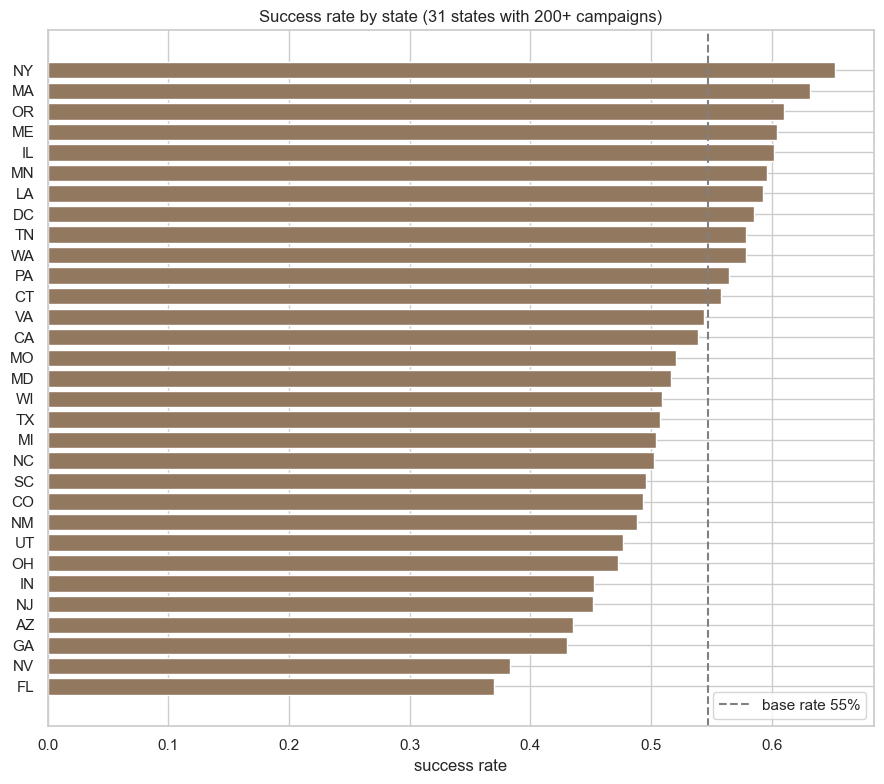

spread across states: 37.0% (FL) -> 65.2% (NY)

top 5 by volume:
state
CA    8213
NY    6626
TX    1846
IL    1714
FL    1407


In [33]:
st = (eda.groupby("state")["success"].agg(["mean", "size"])
         .query("size >= 200").sort_values("mean"))
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(st.index, st["mean"], color=PALETTE[5])
ax.axvline(BASE, ls="--", c="gray", label=f"base rate {BASE:.0%}")
ax.set(title=f"Success rate by state ({len(st)} states with 200+ campaigns)",
       xlabel="success rate")
ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_state.png", dpi=150); plt.show()

print(f"spread across states: {st['mean'].min():.1%} ({st['mean'].idxmin()}) -> "
      f"{st['mean'].max():.1%} ({st['mean'].idxmax()})")
print("\ntop 5 by volume:")
print(eda["state"].value_counts().head(5).to_string())

### 5.6 Reward tiers and reward pricing

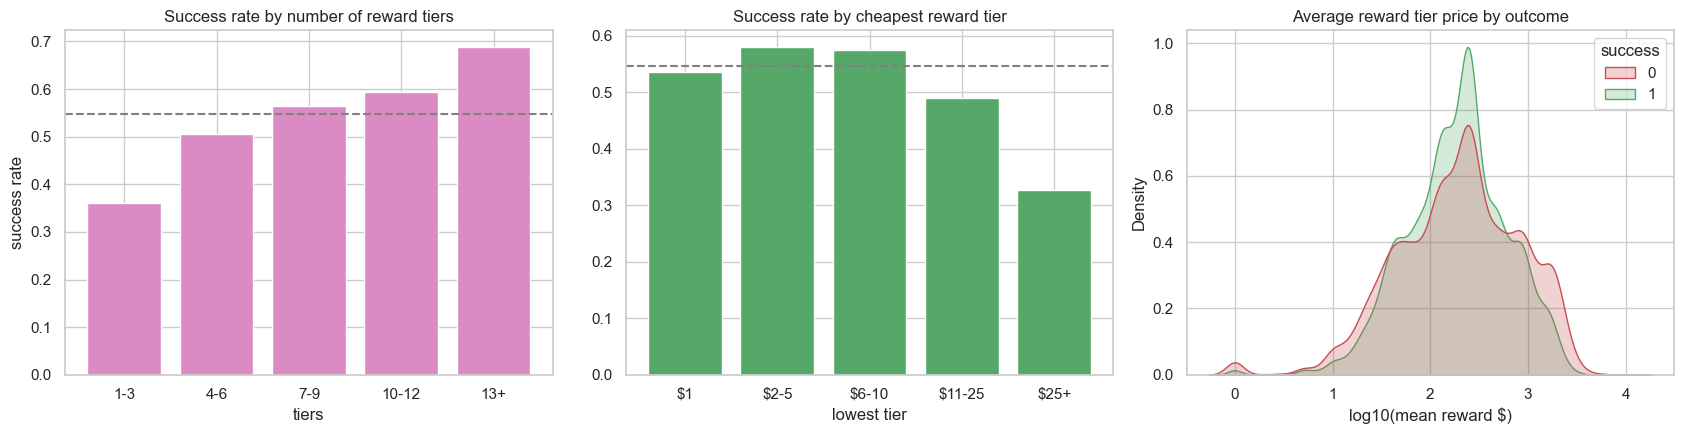

            mean   size
tier_band              
1-3        0.361   3429
4-6        0.506  11049
7-9        0.564  13460
10-12      0.594   6600
13+        0.689   3954

                  mean   size
min_reward_band              
$1               0.536  14878
$2-5             0.581  10351
$6-10            0.575   8381
$11-25           0.490   4070
$25+             0.328    812


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

eda["tier_band"] = pd.cut(eda["n_reward_tiers"], bins=[0, 3, 6, 9, 12, np.inf],
                          labels=["1-3", "4-6", "7-9", "10-12", "13+"])
tb = eda.groupby("tier_band", observed=True)["success"].agg(["mean", "size"])
axes[0].bar(tb.index.astype(str), tb["mean"], color=PALETTE[6])
axes[0].axhline(BASE, ls="--", c="gray")
axes[0].set(title="Success rate by number of reward tiers", xlabel="tiers", ylabel="success rate")

eda["min_reward_band"] = pd.cut(eda["reward_min"], bins=[0, 1, 5, 10, 25, np.inf],
                                labels=["$1", "$2-5", "$6-10", "$11-25", "$25+"])
mb = eda.groupby("min_reward_band", observed=True)["success"].agg(["mean", "size"])
axes[1].bar(mb.index.astype(str), mb["mean"], color=PALETTE[2])
axes[1].axhline(BASE, ls="--", c="gray")
axes[1].set(title="Success rate by cheapest reward tier", xlabel="lowest tier", ylabel="")

sns.kdeplot(data=eda, x=np.log10(eda["reward_mean"]), hue="success", fill=True,
            common_norm=False, palette=[PALETTE[3], PALETTE[2]], ax=axes[2])
axes[2].set(title="Average reward tier price by outcome", xlabel="log10(mean reward $)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_rewards.png", dpi=150); plt.show()

print(tb.assign(mean=lambda d: d["mean"].round(3)).to_string())
print()
print(mb.assign(mean=lambda d: d["mean"].round(3)).to_string())

### 5.7 Launch timing

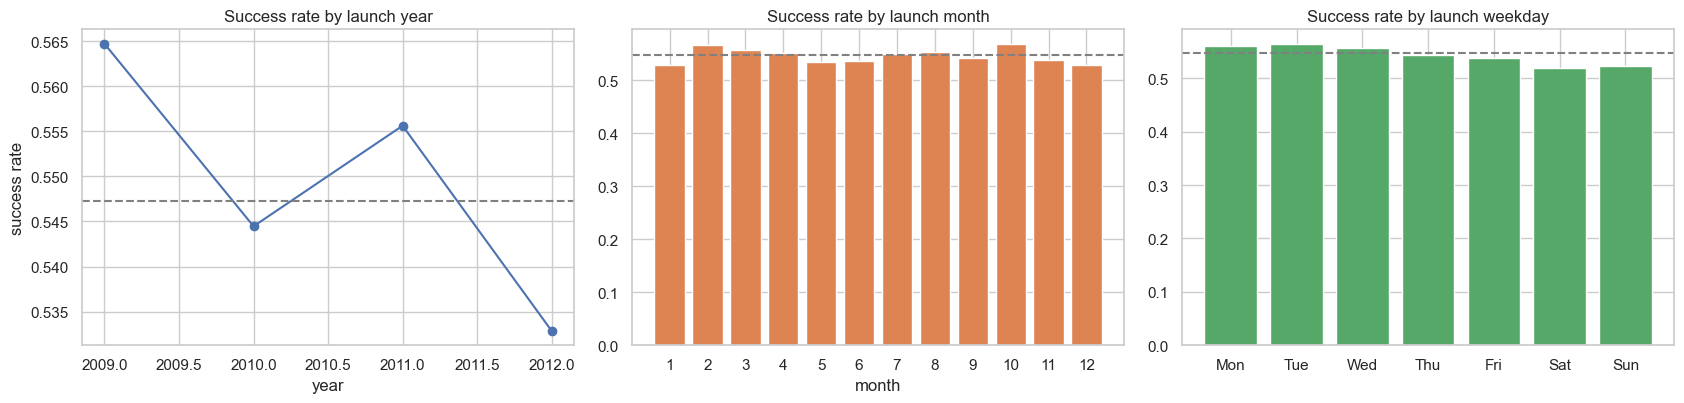

              mean   size
launch_year              
2009         0.565    680
2010         0.544   6961
2011         0.556  19895
2012         0.533  10956


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

yr = eda.groupby("launch_year")["success"].agg(["mean", "size"])
axes[0].plot(yr.index, yr["mean"], marker="o", color=PALETTE[0])
axes[0].axhline(BASE, ls="--", c="gray")
axes[0].set(title="Success rate by launch year", xlabel="year", ylabel="success rate")

mo = eda.groupby("launch_month")["success"].mean()
axes[1].bar(mo.index, mo.values, color=PALETTE[1])
axes[1].axhline(BASE, ls="--", c="gray")
axes[1].set(title="Success rate by launch month", xlabel="month", xticks=range(1, 13))

dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dw = eda.groupby("launch_dow")["success"].mean()
axes[2].bar([dow_names[i] for i in dw.index], dw.values, color=PALETTE[2])
axes[2].axhline(BASE, ls="--", c="gray")
axes[2].set(title="Success rate by launch weekday", xlabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_timing.png", dpi=150); plt.show()

print(yr.assign(mean=lambda d: d["mean"].round(3)).to_string())

### 5.8 Correlation matrix

Spearman (rank) correlation is used throughout: goal, reward prices and the ratio features are all
heavily skewed, so Pearson would mostly measure the influence of a few extreme campaigns. Post-launch
columns are included **for contrast only**, clearly marked, to make the scale of the leakage visible.

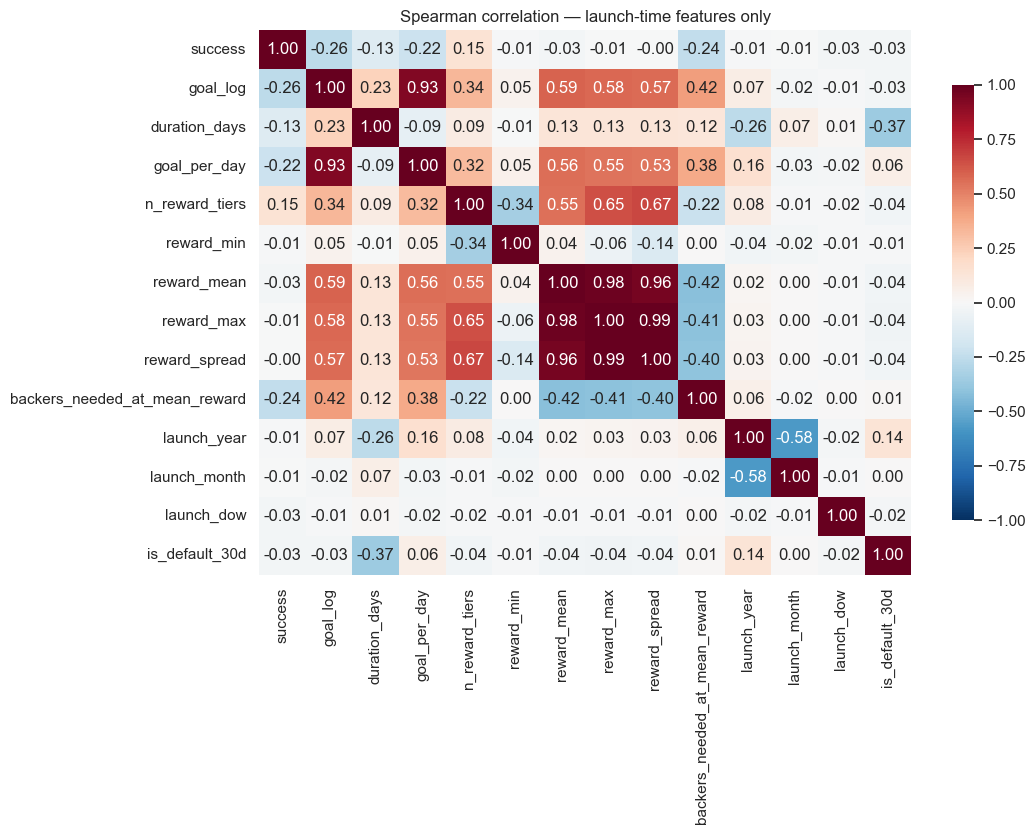

In [36]:
launch_cols = ["success", "goal_log", "duration_days", "goal_per_day", "n_reward_tiers",
               "reward_min", "reward_mean", "reward_max", "reward_spread",
               "backers_needed_at_mean_reward", "launch_year", "launch_month", "launch_dow", "is_default_30d"]

corr = eda[launch_cols].corr(method="spearman")
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=False, cbar_kws={"shrink": .8})
plt.title("Spearman correlation — launch-time features only")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlation.png", dpi=150); plt.show()

In [37]:
ranked = (corr["success"].drop("success").sort_values(key=np.abs, ascending=False)
          .rename("spearman_rho_with_success").to_frame().round(3))
print("launch-time features ranked by |correlation| with success:")
print(ranked.to_string())

launch-time features ranked by |correlation| with success:
                               spearman_rho_with_success
goal_log                                          -0.261
backers_needed_at_mean_reward                     -0.244
goal_per_day                                      -0.216
n_reward_tiers                                     0.147
duration_days                                     -0.129
launch_dow                                        -0.029
is_default_30d                                    -0.028
reward_mean                                       -0.028
reward_min                                        -0.013
launch_year                                       -0.012
reward_max                                        -0.006
launch_month                                      -0.005
reward_spread                                     -0.005


In [38]:
# Leakage contrast: the same correlation for post-launch columns.
leak_cols = ["success", "updates", "update_frequency", "comments", "backers",
             "pledged", "funded percentage"]
leak_corr = df.assign(
    update_frequency=df["updates"] / df["duration"]
)[leak_cols].corr(method="spearman")["success"].drop("success").sort_values(key=np.abs, ascending=False)
print("post-launch columns vs. success (EXCLUDED from the model matrix):")
print(leak_corr.round(3).to_string())
print("\n`updates` correlates more strongly with the outcome than any genuine launch-time feature,")
print("which is exactly why it is quarantined rather than used.")

post-launch columns vs. success (EXCLUDED from the model matrix):
funded percentage    0.862
backers              0.722
pledged              0.704
update_frequency     0.566
updates              0.552
comments             0.469

`updates` correlates more strongly with the outcome than any genuine launch-time feature,
which is exactly why it is quarantined rather than used.


### 5.9 Interaction view: goal x duration

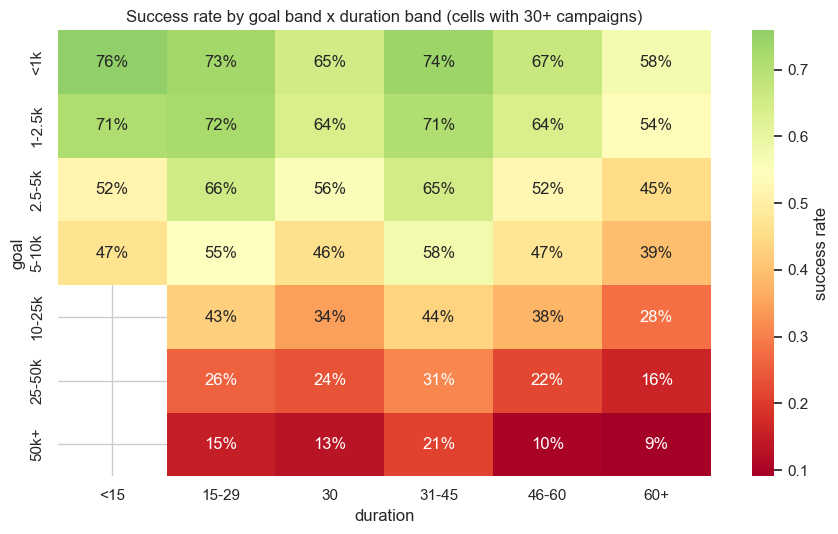

In [39]:
pivot = (eda.pivot_table(index="goal_band", columns="duration_band",
                         values="success", aggfunc="mean", observed=True))
counts = (eda.pivot_table(index="goal_band", columns="duration_band",
                          values="success", aggfunc="size", observed=True))
pivot = pivot.where(counts >= 30)   # suppress cells with thin support

plt.figure(figsize=(9, 5.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="RdYlGn", center=BASE,
            cbar_kws={"label": "success rate"})
plt.title("Success rate by goal band x duration band (cells with 30+ campaigns)")
plt.xlabel("duration"); plt.ylabel("goal")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_goal_duration.png", dpi=150); plt.show()

### 5.10 Findings

**Base rate.** 54.7% of the 38,492 filtered US campaigns succeeded, so the classes are close to
balanced and accuracy is a meaningful headline metric (to be complemented by precision/recall/F1/ROC-AUC).

**Strongest launch-time signals, ranked by Spearman |rho| with `success`:**

| Feature | rho | Reading |
|---|---|---|
| `goal_log` | **-0.261** | The dominant predictor |
| `backers_needed_at_mean_reward` | -0.244 | Same signal, in units a creator can act on |
| `goal_per_day` | -0.216 | Required daily pace |
| `n_reward_tiers` | +0.147 | More tiers, better odds |
| `duration_days` | -0.129 | Shorter is better |
| everything else | < 0.03 | Launch timing and reward *prices* are near-flat |

1. **Goal size dominates.** Success falls monotonically across every goal band: 69.0% under \$1k,
   56.6% at \$2.5-5k, 36.7% at \$10-25k, 13.0% above \$50k. The three strongest features in the
   table are all restatements of goal, which is itself a warning about multicollinearity.
2. **Number of reward tiers matters; tier *prices* do not.** Success climbs steadily with tier count
   (36.1% at 1-3 tiers, 56.4% at 7-9, 68.9% at 13+), but `reward_mean`, `reward_min`, `reward_max`
   and `reward_spread` all have |rho| <= 0.03. Tier *count* is most plausibly a proxy for creator
   preparation rather than a causal lever, which matters for the recommendation stage: "add more
   tiers" is weaker advice than the raw correlation suggests. Entry price shows a mild interior
   optimum — \$2-5 does best (58.1%), a \$1 tier slightly worse (53.6%), and \$25+ clearly worst
   (32.8%).
3. **Duration is negatively related to success, but not monotonically.** The trend is downward
   overall (67.8% under 15 days, 41.6% past 60 days), with one conspicuous exception: the
   exactly-30-day band sits at **53.6%**, *below* the 31-45 day band at 61.0%. 30 days is
   Kickstarter's default, so that band is dominated by creators who accepted the default rather than
   chose a length — a selection effect, not evidence that 30 days is a bad number. An
   `is_default_30d` flag is included in the feature set to let a model separate "chose 30" from
   "accepted the default" (its own marginal rho is only -0.028, so its value, if any, is in
   interaction with goal and category rather than on its own).
4. **Category spans the widest range of any categorical:** Dance 76.1%, Theater 70.5% and Music 67.8%
   at the top; Fashion 32.5%, Technology 38.3% and Publishing 39.3% at the bottom. The 44-point
   spread justifies one-hot encoding rather than collapsing it.
5. **State matters much less than category.** Among states with 200+ campaigns the spread is only
   37.0% (FL) to 65.2% (NY), and volume is heavily concentrated: CA (8,213) and NY (6,626) together
   are 38% of all campaigns. Target encoding is the right weight for it.
6. **Launch timing is close to flat.** Year moves within a 3-point band (56.5% in 2009 to 53.3% in
   2012) and month/weekday effects are small. The dataset covers only 2009-04 to 2012-06, so there is
   not enough history for a real seasonality claim. These features are retained but should not be
   expected to carry much.

**Correlation structure.** The reward statistics are strongly correlated with each other, and
`goal_log` with `goal_per_day` and `backers_needed_at_mean_reward` - expected, since they share
terms. Tree models tolerate this; a linear baseline should use regularization or a reduced subset.

**Data caveats.**
- Reward amounts cap at exactly \$10,000 in the source scrape (it is the max of `reward_min`,
  `reward_mean` *and* `reward_max`), so high-tier pricing is censored.
- `goal` is extreme at the top end (max \$21.47M = 2^31 cents, i.e. an integer-overflow sentinel
  rather than a real goal). The log transform plus rank-based correlation limit the damage, but a
  hard upper clip is worth testing at the modeling stage.

**Leakage, restated.** `funded percentage` (rho = 0.86), `backers` (0.72), `pledged` (0.70),
`update_frequency` (0.57), `updates` (0.55) and `comments` (0.47) all beat every genuine launch-time
feature. That is a symptom, not an opportunity - a campaign that is visibly succeeding attracts
updates and comments. All six stay out of the model matrix.

**Carried into modeling:** the encoded train/test matrices in `data/processed/`, built with the
scaler and encoders fitted on training data only.

In [40]:
print("artifacts written")
for f in sorted(FIG_DIR.glob('*.png')):
    print("  figures/", f.name, sep="")
for f in sorted(PROC_DIR.glob('*.csv')):
    print("  data/processed/", f.name, sep="")

artifacts written
  figures/eda_category.png
  figures/eda_correlation.png
  figures/eda_duration.png
  figures/eda_goal.png
  figures/eda_goal_duration.png
  figures/eda_rewards.png
  figures/eda_state.png
  figures/eda_timing.png
  data/processed/kickstarter_us_clean.csv
  data/processed/test_encoded.csv
  data/processed/train_encoded.csv
